# Example 8.1: Periodic sampling of signals

Let us consider a signal defined by $x(t) = \sin(2\pi f_0 t)$, where $f_0=20\:\text{Hz}$. The signal is analogue (continuous) since it is defined for all possible $t$.

$$
x(t)=\: \mathbf{\sim \sim \sim \sim}
$$


In practical terms, an analogue signal is typically represented as a voltage from a sensor, such as an accelerometer. However, it is not possible to store an analogue signal directly in a computer since it exists continuously over time. To work with it digitally, we need to convert it into discrete values by sampling the signal at specific time intervals. For instance, if we choose a fixed sampling interval of $t_s=0.02  \: $ s,  we store the signal at discrete time points:

$$
\{ \: x[0],x[1],x[2],x[3],\dots \: \},\quad x[n]=x(n \cdot t_s)
$$

In the code, we use a record duration of $T=100$ s. The sample times are $t_n=n t_s=n/f_s$ for $0\leq t_n<T$.

This means that we store 50 samples per second, and the sampling rate is $f_s=50 \: \text{Hz}$. To optimize storage, we aim to store as few samples as possible while still capturing all the relevant information from the original signal.

## Aliasing

When gathering measurement data, one needs to be aware of aliasing (folding). Let us consider a sine wave defined by

$$x(t) = \sin(2 \pi f_0 t)  $$

The sine is periodic, so we can add $2\pi m$ without changing the value:

$$x[n] = \sin(2 \pi f_0 n t_s) = \sin(2 \pi f_0 n t_s + 2\pi m)$$

Here $t_s$ is the sampling interval, and $m$ is an integer. For any integer $k$, choose $m=kn$. We can now introduce $f_s=1/t_s$:

$$x[n] = \sin \left(2\pi(f_0 n t_s + kn)\right)
       = \sin \left(2\pi(f_0 + kf_s)n t_s\right).$$

The equation above means that we will get the same sampling values when sampling a waveform with frequencies $f_0$ and $f_0 +  kf_s$. Let us study this further by considering a sampling rate of 50 Hz. The equation above implies that waveforms with frequencies $f_0=20,70,120,170,\ldots$ Hz will provide the same sampling values, which makes it impossible to tell which of the frequencies the waveform has from the gathered samples. This means that it is essential that the signal does not have a frequency content at or above 25 Hz when sampling at 50 Hz. This is called the Nyquist frequency:

$$f_{Nyq}=f_s/2$$

This important limit needs to be respected when converting an analogue signal to digital.


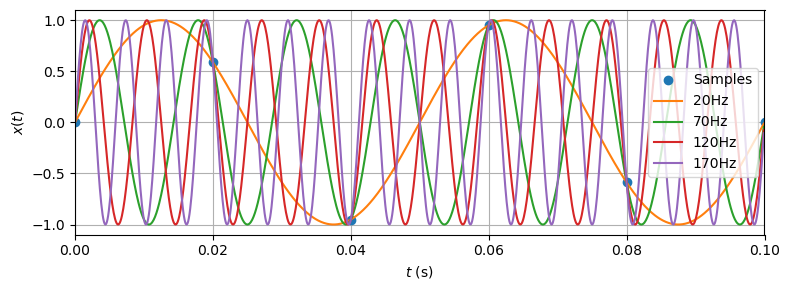

In [21]:
import numpy as np
from matplotlib import pyplot as plt
from scipy import signal as spsi

f0 = 20
fs = 50 # Sample rate

T = 100 # Record duration (s)
t = np.arange(0,T,1/fs)
y = np.sin(2*np.pi*f0*t)

tf = np.arange(0,0.1,1/10000)

plt.figure(figsize=(8,3))
plt.plot(t,y,'o',label='Samples')

# Plot signals at f0 + k*fs: 20, 70, 120 and 170 Hz
for k in range(4):
    plt.plot(tf,np.sin(2*np.pi*tf*(f0+k*fs)),label = str(f0+k*fs) + "Hz" )
plt.legend()
plt.grid()
plt.ylabel("$x(t)$");
plt.xlabel("$t$ (s)");
plt.xlim(0,0.1) # Show only the first 0.1 s of the record
plt.tight_layout()

## Sampling a 20 Hz signal

We can also study the aliasing phenomenon by sampling a waveform with different sampling frequencies. Let us consider a harmonic function with a frequency of 20 Hz. The code below shows the waveform with a very high sampling rate, which makes it very close to the analogue signal, and the waveform sampled at 22 Hz.

The figure illustrates that it is difficult to draw the correct graph based on the gathered samples, and most people would intuitively draw a graph with a lower frequency than 20 Hz based on the points available. The bottom plot shows the Fourier amplitudes of the real waveform and the Fourier amplitudes of the samples gathered at 22 Hz. The peak of the Fourier amplitudes of the sampled signal is far lower than it should be, and this illustrates that we have collected samples at too low sampling rate. This phenomenon is called aliasing or folding.

The highest frequency we can capture without aliasing (folding) is below $f_s/2$. This implies that we need to sample the 20 Hz signal at a sampling rate higher than 40 Hz. First run the code at 22 Hz to see aliasing, then change `fs` to 41 Hz and run it again.

We use a record duration of `T = 100` seconds. Changing `fs` changes the number of sampled data points while keeping the duration fixed. The densely sampled reference covers the same duration. The time plot shows only the first second to make the oscillations visible; the FFT uses the entire record, giving a frequency resolution of $\Delta f=1/T=0.01$ Hz.


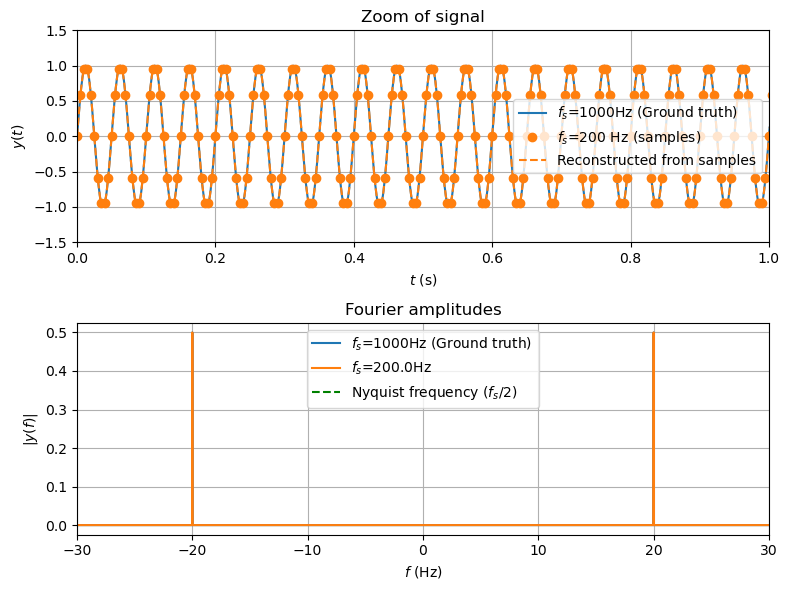

In [28]:
# Try:
# fs=40 Hz
# fs=41 Hz
# fs=35 Hz
# fs=200 Hz

fs = 200.0

# Do not change code below
T = 100 # Record duration (s)
f0 = 20.0

tc = np.arange(0,T,1/1000) # 1000 Hz (almost continuous sampled)
yc = np.sin(2*np.pi*f0*tc)

t = np.arange(0,T,1/fs)

y = np.sin(2*np.pi*f0*t)

y_fft = np.fft.fftshift(np.fft.fft(y))/len(y)
freq = np.fft.fftshift(np.fft.fftfreq(len(y),d=1/fs))

yc_fft = np.fft.fftshift(np.fft.fft(yc))/len(yc)
freqc = np.fft.fftshift(np.fft.fftfreq(len(tc), d=1/1000))
    
yi, ti = spsi.resample(y,len(tc),t=t)

fig, axs = plt.subplots(2,1,figsize=(8,6))
axs[0].plot(tc,yc, label= "$f_s$=" + "1000" + "Hz (Ground truth)")
axs[0].set_title("Zoom of signal")
axs[0].plot(t,y,'o',color='C1',label=fr'$f_s$={fs:g} Hz (samples)')
axs[0].plot(ti,yi,'--',color='C1',label='Reconstructed from samples')
axs[0].set_xlim(0,min(1,T)) # Show only the first second; the FFT uses all T seconds
axs[0].set_ylim(-1.5,1.5)
axs[0].set_ylabel("$y(t)$")
axs[0].set_xlabel("$t$ (s)")
axs[0].legend()
axs[0].grid(True)

axs[1].set_title("Fourier amplitudes")
axs[1].plot(freqc,np.abs(yc_fft),label= "$f_s$=" + "1000" + "Hz (Ground truth) ")
axs[1].plot(freq,np.abs(y_fft),label= "$f_s$=" + str(fs) + "Hz")
axs[1].set_ylabel("$|y(f)|$")
axs[1].set_xlabel("$f$ (Hz)")
axs[1].vlines(0.5*fs,0,0.5,linestyle='--',color='green',label='Nyquist frequency ($f_s/2$)')
axs[1].vlines(-0.5*fs,0,0.5,linestyle='--',color='green')
axs[1].set_xlim(-30,30)
axs[1].legend()
axs[1].grid(True)
plt.tight_layout()


Try to reduce or increase the sampling rate and study the result. At 35 Hz, the 20 Hz signal appears at 15 Hz in the Fourier amplitudes; at 41 Hz, its peak remains at 20 Hz.

We conclude that setting the sample rate correctly *before* performing measurements is very important. For a sample rate $f_s$ we can only reconstruct the frequency content in the range $ \left( \: -\dfrac{f_s}{2}, \dfrac{f_s}{2}  \: \right)$.